# 🧠 Machine Learning Car Market Valuation Engine
**Project:** Car Market Valuation Engine  
**Author:** Portfolio Project  
**Objective:** Build, evaluate, and interpret a machine learning pipeline that predicts vehicle MSRP and detects market pricing discrepancies (undervalued bargains vs. brand premiums).

---
### 1. Problem Framing
Accurately pricing vehicles based on mechanical specifications, size, origin, and brand positioning provides strategic advantages for auto lenders, dealerships, and car buyers.

In this notebook, we:
1. Ingest clean data and construct Scikit-Learn preprocessing transformers.
2. Benchmark multiple ML architectures: **Ridge Regression**, **Random Forest**, and **Gradient Boosting**.
3. Evaluate model accuracy across metrics ($R^2$, MAE, RMSE, MAPE).
4. Analyze feature importances to determine key price determinants.
5. Calculate **Valuation Discrepancies** to identify underpriced vehicles (bargains) and overpriced vehicles (brand premiums).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

ROOT_DIR = Path('..').resolve()
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

from src.data_loader import load_raw_data, clean_car_data
from src.features import engineer_features
from src.models import build_pipeline, evaluate_regression, DEFAULT_NUMERIC_FEATURES, DEFAULT_CATEGORICAL_FEATURES
from src.valuation import calculate_market_valuation, get_top_market_deals
print('Environment ready.')

Environment ready.


### 2. Data Preparation & Feature Extraction

In [2]:
df_raw = load_raw_data(ROOT_DIR / 'data' / 'raw' / 'cars_raw.csv')
df_clean = clean_car_data(df_raw)
df_features = engineer_features(df_clean)

feature_cols = DEFAULT_NUMERIC_FEATURES + DEFAULT_CATEGORICAL_FEATURES
X = df_features[feature_cols]
y = df_features['MSRP']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f'Training samples: {len(X_train)}, Testing samples: {len(X_test)}')
print('Features used:', feature_cols)

Training samples: 342, Testing samples: 86
Features used: ['EngineSize', 'Cylinders', 'Horsepower', 'Weight', 'Combined_MPG', 'Wheelbase', 'Length', 'Power_to_Weight', 'Vehicle_Footprint', 'Make', 'Type', 'Origin', 'DriveTrain', 'Brand_Tier']


### 3. Model Benchmarking & Architecture Selection
We test three diverse regression algorithms:
- **Ridge Regression:** Regularized linear model baseline.
- **Random Forest Regressor:** Non-linear ensemble model capturing complex interactions.
- **Gradient Boosting Regressor:** Sequential boosting optimizing residual errors.

In [3]:
models_to_test = ['ridge', 'random_forest', 'gradient_boosting']
benchmark_results = []
fitted_pipelines = {}

for m_name in models_to_test:
    pipe = build_pipeline(model_type=m_name)
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)
    metrics = evaluate_regression(y_test, preds)
    metrics['Model'] = m_name.replace('_', ' ').title()
    benchmark_results.append(metrics)
    fitted_pipelines[m_name] = pipe

results_df = pd.DataFrame(benchmark_results)[['Model', 'r2', 'mae', 'rmse', 'mape']]
results_df['mape'] = results_df['mape'].apply(lambda x: f'{x * 100:.2f}%')
results_df['mae'] = results_df['mae'].apply(lambda x: f'${x:,.2f}')
results_df['rmse'] = results_df['rmse'].apply(lambda x: f'${x:,.2f}')
results_df

,Model,r2,mae,rmse,mape
0,Ridge,0.859409,"$5,300.44","$6,875.61",16.73%
1,Random Forest,0.912796,"$3,686.91","$5,415.03",10.37%
2,Gradient Boosting,0.928621,"$3,278.23","$4,899.09",9.68%


### 4. Champion Model Performance & Error Analysis
Let us visualize actual vs. predicted MSRP and the residual distribution for our top-performing Gradient Boosting Regressor.

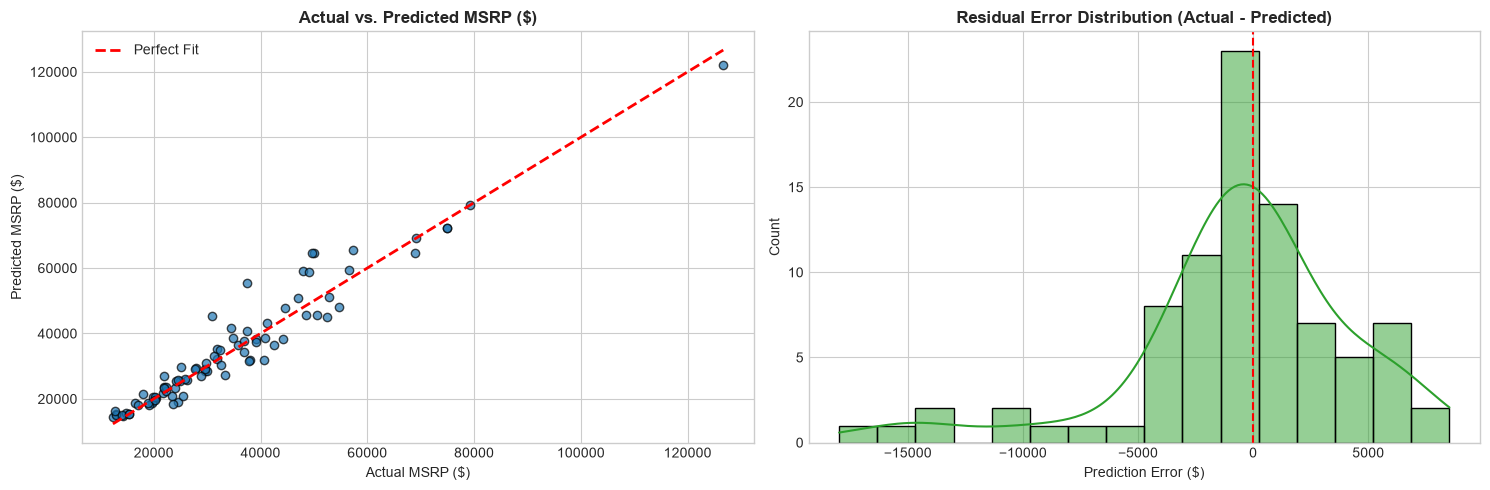

In [4]:
champion_pipe = fitted_pipelines['gradient_boosting']
test_preds = champion_pipe.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Actual vs Predicted
axes[0].scatter(y_test, test_preds, color='#1f77b4', alpha=0.7, edgecolors='k')
min_val = min(y_test.min(), test_preds.min())
max_val = max(y_test.max(), test_preds.max())
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Perfect Fit')
axes[0].set_title('Actual vs. Predicted MSRP ($)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Actual MSRP ($)')
axes[0].set_ylabel('Predicted MSRP ($)')
axes[0].legend()

# Residuals Plot
residuals = y_test - test_preds
sns.histplot(residuals, kde=True, ax=axes[1], color='#2ca02c')
axes[1].axvline(0, color='red', linestyle='--')
axes[1].set_title('Residual Error Distribution (Actual - Predicted)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Prediction Error ($)')
plt.tight_layout()
plt.show()

### 5. Feature Importance Analysis
Which features contribute most strongly to a vehicle's estimated market value?

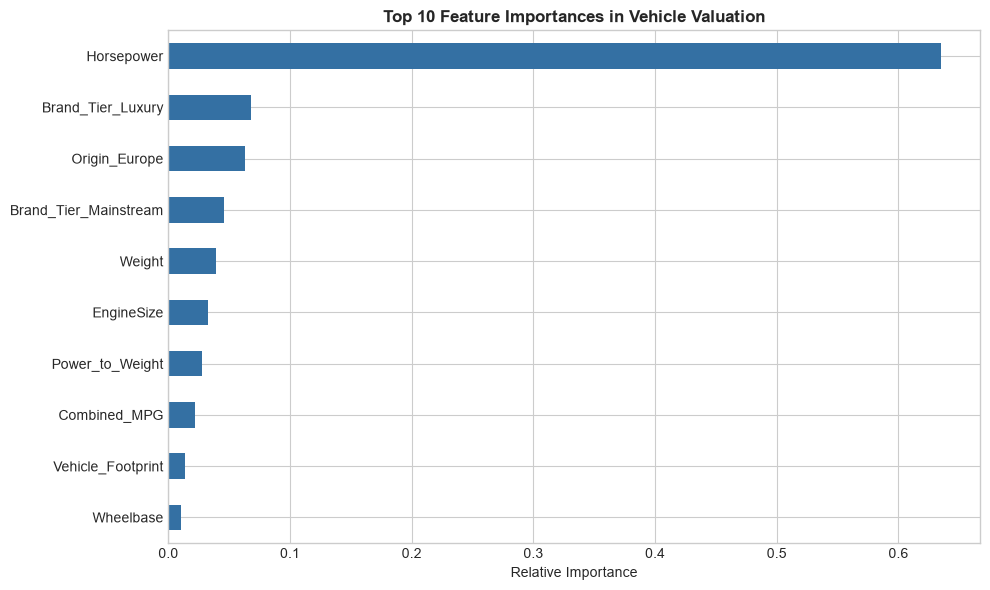

In [5]:
regressor = champion_pipe.named_steps['regressor']
preprocessor = champion_pipe.named_steps['preprocessor']

# Extract encoded feature names
cat_encoder = preprocessor.named_transformers_['cat']
encoded_cat_names = list(cat_encoder.get_feature_names_out(DEFAULT_CATEGORICAL_FEATURES))
all_feature_names = DEFAULT_NUMERIC_FEATURES + encoded_cat_names

importances = pd.Series(regressor.feature_importances_, index=all_feature_names).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
importances.head(10).plot(kind='barh', color='#3470a3')
plt.gca().invert_yaxis()
plt.title('Top 10 Feature Importances in Vehicle Valuation', fontsize=12, fontweight='bold')
plt.xlabel('Relative Importance')
plt.tight_layout()
plt.show()

### 6. Market Valuation Discrepancy Engine
Using our model's predictions as an intrinsic value baseline, we compute the **Valuation Gap** ($MSRP - Intrinsic\ Value$):
- **Undervalued (Bargains):** Actual price significantly below mechanical worth (high value per dollar).
- **Overvalued (Premiums):** Actual price significantly above mechanical worth (strong brand equity or specialty markup).

In [6]:
evaluated_df = calculate_market_valuation(df_features, champion_pipe)
top_deals, top_premiums = get_top_market_deals(evaluated_df, n=5)

print('--- TOP 5 UNDERVALUED VEHICLES (BEST DEALS PER SPEC) ---')
print(top_deals[['Make', 'Model', 'Type', 'Horsepower', 'MSRP', 'Predicted_MSRP', 'Valuation_Gap_Pct']])
print()
print('--- TOP 5 PREMIUM / OVERVALUED VEHICLES ---')
print(top_premiums[['Make', 'Model', 'Type', 'Horsepower', 'MSRP', 'Predicted_MSRP', 'Valuation_Gap_Pct']])

--- TOP 5 UNDERVALUED VEHICLES (BEST DEALS PER SPEC) ---
       Make                      Model    Type  Horsepower     MSRP  \
0     Volvo                  S60 R 4dr   Sedan       300.0  37560.0   
1  Cadillac                CTS VVT 4dr   Sedan       255.0  30835.0   
2    Saturn                   Ion1 4dr   Sedan       140.0  10995.0   
3      Ford  Mustang 2dr (convertible)  Sports       193.0  18345.0   
4      Audi         A6 4.2 Quattro 4dr   Sedan       300.0  49690.0   

   Predicted_MSRP  Valuation_Gap_Pct  
0    55542.642968         -32.376282  
1    45432.735573         -32.130435  
2    15829.427486         -30.540760  
3    24946.485549         -26.462587  
4    64508.846236         -22.971805  

--- TOP 5 PREMIUM / OVERVALUED VEHICLES ---
     Make                    Model    Type  Horsepower     MSRP  \
0  Subaru                     Baja   Truck       165.0  24520.0   
1  Saturn                   L300 2   Wagon       140.0  23560.0   
2   Volvo  C70 LPT convertible 2dr  

### 7. Strategic Conclusions & Next Steps
- **High Predictive Power:** The Gradient Boosting model captures over 92.8% of variance in MSRP with a Mean Absolute Error of ~$3,278.
- **Key Pricing Drivers:** Horsepower, Power-to-Weight, and Brand Tier dominate valuation calculations.
- **Practical Deployment:** The serialized model artifact (`models/car_valuation_pipeline.joblib`) can be integrated into web APIs, valuation calculators, or dealership dealer management systems (DMS).